<a href="https://colab.research.google.com/github/Sandersonav/Aula020725/blob/main/Projeto_ML_California_sandersonarantes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import sys
import numpy as np, pandas as pd, matplotlib, sklearn

print("Python em uso:", sys.executable)   # deve apontar para dentro de .venv
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python em uso: /usr/bin/python3
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0
scikit-learn: 1.6.1


In [4]:
import numpy as np

y_real = np.array([200, 210, 190, 205, 195])    # preços em milhares

# Modelo A: erros pequenos e parecidos
pred_A = np.array([210, 200, 200, 195, 205])    # erro = 10 em todos

# Modelo B: acerta quase tudo, mas erra feio em UM distrito
pred_B = np.array([200, 210, 190, 205, 145])    # erros = 0, 0, 0, 0, 50

def mae(y, p):  return np.mean(np.abs(p - y))
def rmse(y, p): return np.sqrt(np.mean((p - y) ** 2))

for nome, p in [("A", pred_A), ("B", pred_B)]:
    print(f"Modelo {nome}: MAE = {mae(y_real, p):.1f} | RMSE = {rmse(y_real, p):.1f}")

Modelo A: MAE = 10.0 | RMSE = 10.0
Modelo B: MAE = 10.0 | RMSE = 22.4


In [33]:
from pathlib import Path
from urllib.request import urlretrieve
import pandas as pd

PASTA_DADOS = Path("data")                      # pasta onde o CSV ficará
ARQUIVO = PASTA_DADOS / "housing.csv"           # caminho completo do arquivo
URL_CSV = ("https://raw.githubusercontent.com/ageron/handson-ml/"
           "master/datasets/housing/housing.csv")

def buscar_dados(destino=ARQUIVO, url=URL_CSV):
    """Baixa o CSV só se ele ainda não existir localmente."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)  # cria a pasta data/
    if not destino.exists():                           # evita baixar de novo
        print("Baixando o CSV de referência...")
        urlretrieve(url, destino)
    else:
        print("Usando arquivo local:", destino)
    return destino

def carregar_dados(caminho=ARQUIVO):
    """Lê o CSV e devolve um DataFrame do pandas."""
    return pd.read_csv(caminho)

buscar_dados()
housing = carregar_dados()


Usando arquivo local: data/housing.csv


In [6]:
COLUNAS_ESPERADAS = {
    "longitude", "latitude", "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households", "median_income",
    "median_house_value", "ocean_proximity",
}
faltando = COLUNAS_ESPERADAS - set(housing.columns)
assert not faltando, f"Colunas faltando: {sorted(faltando)}"
print("Esquema validado!")

Esquema validado!


In [7]:
display(housing.head())                       # 5 primeiras linhas
display(housing.sample(5, random_state=42))   # 5 linhas aleatórias (reprodutível)
housing.info()                                # tipos e valores não nulos
display(housing.describe())                   # resumo estatístico das numéricas
print(housing["ocean_proximity"].value_counts(dropna=False))
print(housing.isna().sum())                   # ausentes por coluna

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20046,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,47700.0,INLAND
3024,-119.46,35.14,30.0,2943.0,NaN,1565.0,584.0,2.5313,45800.0,INLAND
15663,-122.44,37.80,52.0,3830.0,NaN,1310.0,963.0,3.4801,500001.0,NEAR BAY
20484,-118.72,34.28,17.0,3051.0,NaN,1705.0,495.0,5.7376,218600.0,<1H OCEAN
9814,-121.93,36.62,34.0,2351.0,NaN,1063.0,428.0,3.7250,278000.0,NEAR OCEAN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


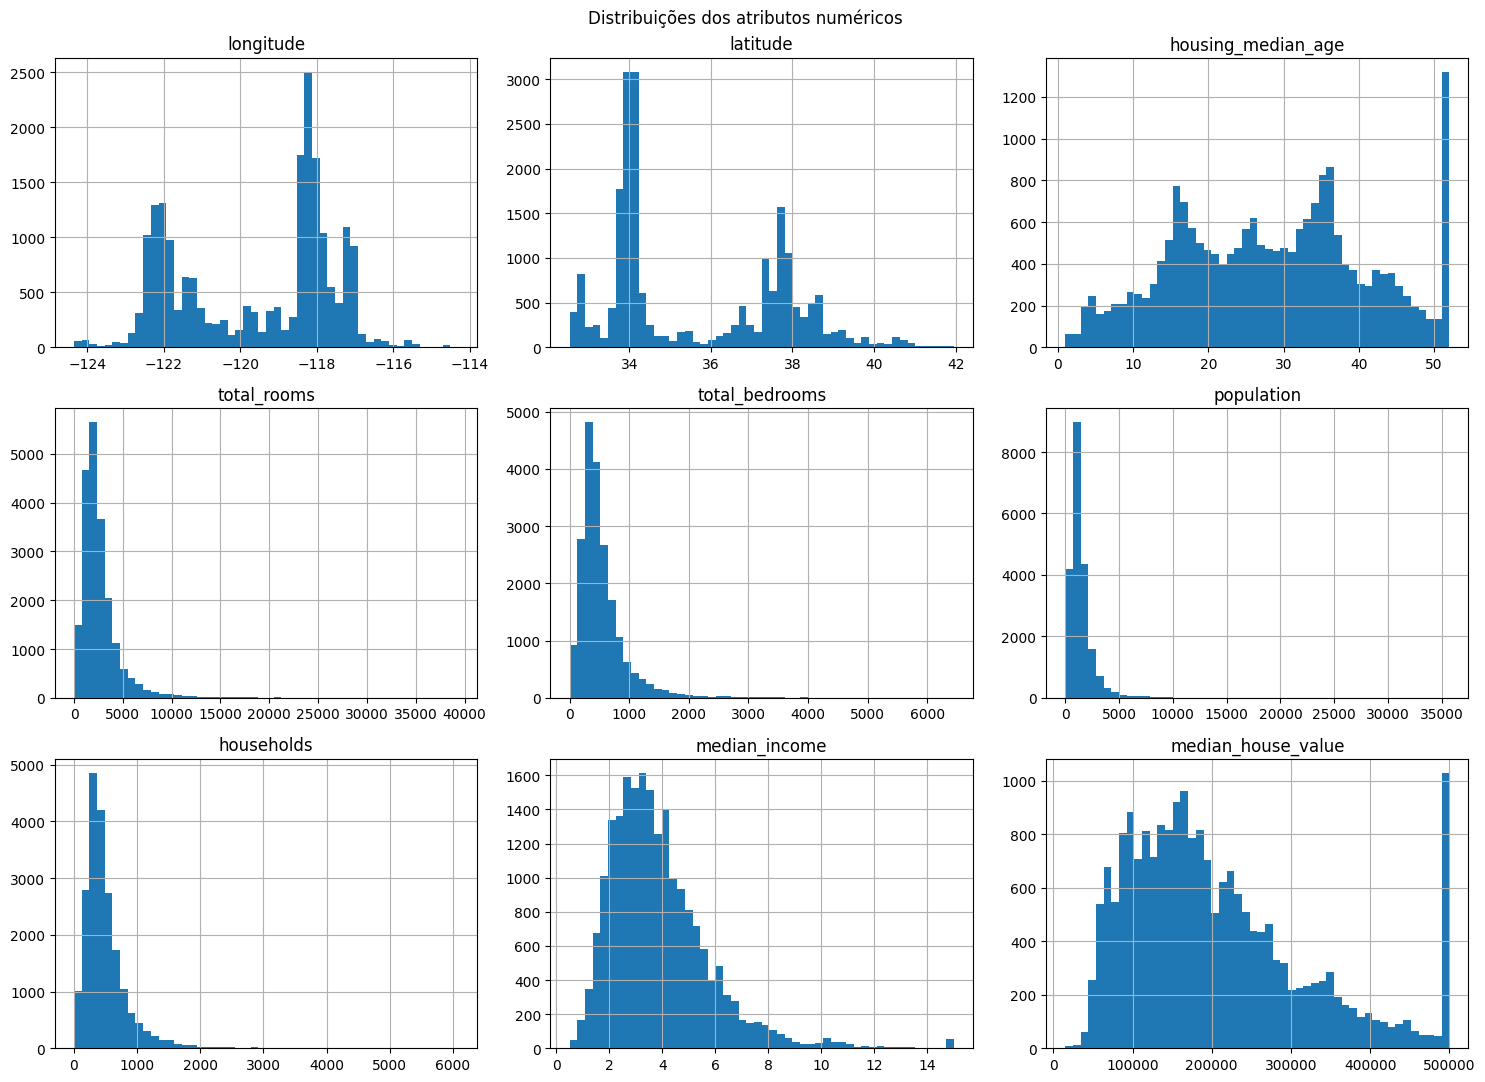

In [8]:
import matplotlib.pyplot as plt

housing.hist(bins=50, figsize=(15, 11))
plt.suptitle("Distribuições dos atributos numéricos")
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import hashlib
from sklearn.model_selection import train_test_split

# 1) Manual: embaralha índices e corta por proporção
def split_train_test(data, test_ratio=0.2, seed=42):
    gerador = np.random.default_rng(seed)             # gerador com semente fixa
    indices = gerador.permutation(len(data))          # ordem embaralhada
    n_teste = int(len(data) * test_ratio)             # tamanho do teste
    return data.iloc[indices[n_teste:]], data.iloc[indices[:n_teste]]

# 2) Por ID: o hash decide se a linha vai para o teste
def test_set_check(identifier, test_ratio=0.2):
    h = hashlib.md5(str(identifier).encode("utf-8")).digest()
    numero = int.from_bytes(h[-4:], "big")            # últimos 4 bytes -> inteiro
    return numero < test_ratio * 2**32                # fração do espaço de hash

def split_train_test_by_id(data, test_ratio, id_column):
    ids = data[id_column]
    no_teste = ids.apply(lambda i: test_set_check(i, test_ratio))
    return data.loc[~no_teste], data.loc[no_teste]

housing_id = housing.reset_index()                    # cria a coluna "index" como ID
train_a, test_a = split_train_test(housing)
train_b, test_b = split_train_test_by_id(housing_id, 0.2, "index")
train_c, test_c = train_test_split(housing, test_size=0.2, random_state=42)
print(len(train_a), len(test_a), len(test_b), len(test_c))

16512 4128 4156 4128


In [10]:
housing_cat = housing.copy()
housing_cat["income_cat"] = pd.cut(
    housing_cat["median_income"],
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],   # limites das 5 faixas
    labels=[1, 2, 3, 4, 5],
)
# income_cat serve só para estratificar. Não será feature.

# Estratificado com train_test_split
strat_train, strat_test = train_test_split(
    housing_cat, test_size=0.2, random_state=42,
    stratify=housing_cat["income_cat"],
)

# Equivalente com a classe do livro
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for idx_treino, idx_teste in split.split(housing_cat, housing_cat["income_cat"]):
    strat_train_ss = housing_cat.iloc[idx_treino]
    strat_test_ss = housing_cat.iloc[idx_teste]

# Comparação: base total x estratificado x aleatório puro
_, rand_test = train_test_split(housing_cat, test_size=0.2, random_state=42)

def prop(df):
    return df["income_cat"].value_counts(normalize=True).sort_index()

comp = pd.DataFrame({
    "Total": prop(housing_cat),
    "Estratificado": prop(strat_test),
    "Aleatório": prop(rand_test),
})
comp["Erro aleat. %"] = 100 * (comp["Aleatório"] / comp["Total"] - 1)
comp["Erro estrat. %"] = 100 * (comp["Estratificado"] / comp["Total"] - 1)
display(comp)

,Total,Estratificado,Aleatório,Erro aleat. %,Erro estrat. %
income_cat,,,,,
1,0.039826,0.039971,0.040213,0.973236,0.364964
2,0.318847,0.318798,0.324370,1.732260,-0.015195
3,0.350581,0.350533,0.358527,2.266446,-0.013820
4,0.176308,0.176357,0.167393,-5.056334,0.027480
5,0.114438,0.114341,0.109496,-4.318374,-0.084674


In [11]:
for conjunto in (strat_train, strat_test):
    conjunto.drop("income_cat", axis=1, inplace=True)

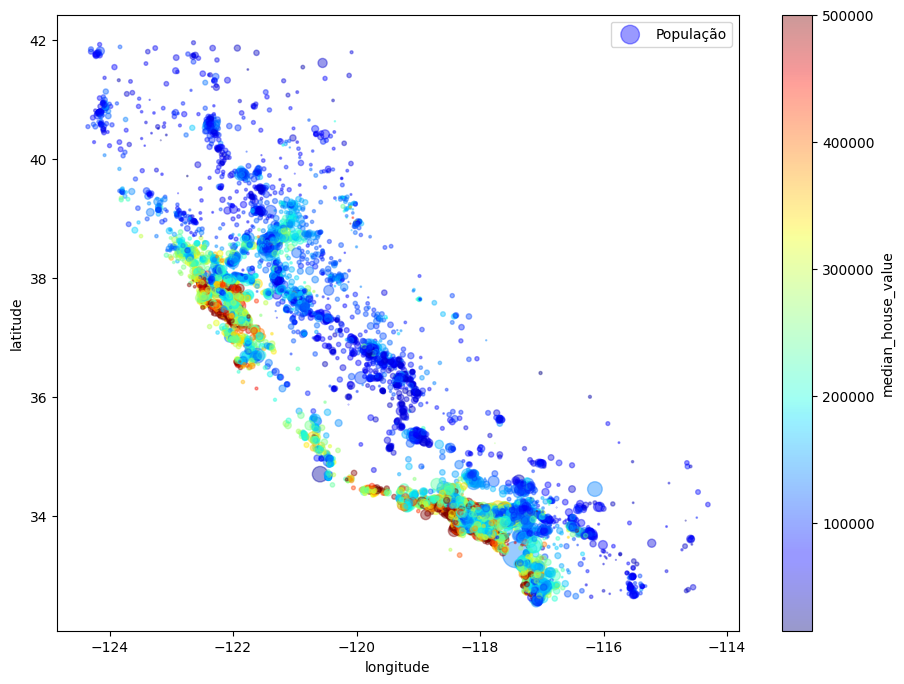

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64


In [12]:
exploracao = strat_train.copy()   # cópia: não mexe no treino original

# Mapa: tamanho = população, cor = preço
ax = exploracao.plot(
    kind="scatter", x="longitude", y="latitude", alpha=0.4, figsize=(11, 8),
    s=exploracao["population"] / 100, label="População",
    c="median_house_value", cmap="jet", colorbar=True,
)
plt.legend(); plt.show()

# Correlação de Pearson com o alvo
corr = exploracao.select_dtypes(include="number").corr()
print(corr["median_house_value"].sort_values(ascending=False))

In [13]:
exploracao["rooms_per_household"] = exploracao["total_rooms"] / exploracao["households"]
exploracao["bedrooms_ratio"] = exploracao["total_bedrooms"] / exploracao["total_rooms"]
exploracao["people_per_household"] = exploracao["population"] / exploracao["households"]
print(exploracao.select_dtypes(include="number").corr()["median_house_value"]
      .sort_values(ascending=False))

median_house_value      1.000000
median_income           0.687151
rooms_per_household     0.146255
total_rooms             0.135140
housing_median_age      0.114146
households              0.064590
total_bedrooms          0.047781
people_per_household   -0.021991
population             -0.026882
longitude              -0.047466
latitude               -0.142673
bedrooms_ratio         -0.259952
Name: median_house_value, dtype: float64


In [14]:
# Preditores (X) e alvo (y) são tratados de forma diferente
X_train = strat_train.drop("median_house_value", axis=1)   # drop devolve uma CÓPIA
y_train = strat_train["median_house_value"].copy()
X_test = strat_test.drop("median_house_value", axis=1)
y_test = strat_test["median_house_value"].copy()

In [15]:
from sklearn.impute import SimpleImputer

X_num = X_train.drop("ocean_proximity", axis=1)     # a mediana só existe para números
imputer = SimpleImputer(strategy="median")
imputer.fit(X_num)                                   # APRENDE as medianas (só no treino)

print(imputer.statistics_)                           # medianas guardadas
print(X_num.median().values)                         # devem ser idênticas
X_imp = imputer.transform(X_num)                     # substitui NaN pela mediana aprendida

[-118.51      34.26      29.      2119.       433.      1164.
  408.         3.54155]
[-118.51      34.26      29.      2119.       433.      1164.
  408.         3.54155]


In [16]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

cat = X_train[["ocean_proximity"]]                   # colchetes duplos: continua DataFrame 2D

ord_enc = OrdinalEncoder()
print(ord_enc.fit_transform(cat)[:5].ravel())        # 0, 1, 2, ... (ordem alfabética)

oh_enc = OneHotEncoder()
cat_1hot = oh_enc.fit_transform(cat)                 # matriz ESPARSA
print(oh_enc.categories_)
print(cat_1hot.toarray()[:3])                        # converte para densa só para olhar

[1. 4. 1. 4. 0.]
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]]


In [17]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

renda = np.array([[1.5], [3.0], [4.5], [6.0], [100.0]])   # 100 = erro de digitação
print("MinMax:    ", MinMaxScaler().fit_transform(renda).ravel().round(3))
print("Standard.: ", StandardScaler().fit_transform(renda).ravel().round(3))

MinMax:     [0.    0.015 0.03  0.046 1.   ]
Standard.:  [-0.558 -0.519 -0.48  -0.441  1.998]


In [18]:
from sklearn.base import BaseEstimator, TransformerMixin

class RazoesHabitacionais(BaseEstimator, TransformerMixin):
    """Acrescenta razões por domicílio. Recebe e devolve um DataFrame."""
    def __init__(self, add_bedrooms_ratio=True):   # hiperparâmetro "liga/desliga"
        self.add_bedrooms_ratio = add_bedrooms_ratio

    def fit(self, X, y=None):
        return self                                 # nada a aprender

    def transform(self, X):
        X = X.copy()
        dom = X["households"].replace(0, np.nan)    # evita divisão por zero
        X["rooms_per_household"] = X["total_rooms"] / dom
        X["people_per_household"] = X["population"] / dom
        if self.add_bedrooms_ratio:
            X["bedrooms_ratio"] = X["total_bedrooms"] / X["total_rooms"].replace(0, np.nan)
        return X

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

num_attribs = list(X_num.columns) + ["rooms_per_household",
                                     "people_per_household", "bedrooms_ratio"]
cat_attribs = ["ocean_proximity"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # 1º: preenche NaN
    ("scaler", StandardScaler()),                    # 2º: padroniza
])

preprocessador = ColumnTransformer([
    ("num", num_pipeline, num_attribs),              # números: imputa e escala
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attribs),
])

prep_completo = Pipeline([
    ("razoes", RazoesHabitacionais()),               # cria as razões
    ("preparo", preprocessador),                     # trata cada tipo de coluna
])

X_train_prep = prep_completo.fit_transform(X_train)  # APRENDE no treino
X_test_prep = prep_completo.transform(X_test)        # só APLICA no teste
print(X_train_prep.shape)                            # (16512, 16)

(16512, 16)


In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

def rmse(y_real, y_prev):
    """RMSE = raiz do erro quadrático médio."""
    return np.sqrt(mean_squared_error(y_real, y_prev))

modelos = {
    "Baseline (média)":  DummyRegressor(strategy="mean"),
    "Regressão Linear":  LinearRegression(),
    "Árvore de Decisão": DecisionTreeRegressor(random_state=42),
    "Floresta Aleatória": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train_prep, y_train)                 # APRENDE no treino
    prev_treino = modelo.predict(X_train_prep)        # prevê o próprio treino
    resultados.append({"Modelo": nome, "RMSE treino": rmse(y_train, prev_treino)})

display(pd.DataFrame(resultados).sort_values("RMSE treino"))

,Modelo,RMSE treino
2,Árvore de Decisão,0.000000
3,Floresta Aleatória,18656.461170
1,Regressão Linear,68160.924355
0,Baseline (média),115697.793645


In [21]:
amostra = X_train.iloc[:5]
amostra_prep = prep_completo.transform(amostra)       # transform, NÃO fit_transform
print("Previsões:", modelos["Regressão Linear"].predict(amostra_prep).round(0))
print("Reais:    ", list(y_train.iloc[:5]))

Previsões: [ 83649. 305815. 150013. 188096. 241840.]
Reais:     [72100.0, 279600.0, 82700.0, 112500.0, 238300.0]


In [22]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

def construir_pipeline(estimador):
    """Pipeline completo: razões + preparo + modelo."""
    return Pipeline([
        ("razoes", RazoesHabitacionais()),
        ("preparo", clone(preprocessador)),   # clone: cópia limpa, não ajustada
        ("modelo", estimador),
    ])

resultados_cv = []
for nome, modelo in modelos.items():
    pipe = construir_pipeline(clone(modelo))
    scores = cross_val_score(
        pipe, X_train, y_train, cv=5,
        scoring="neg_mean_squared_error", n_jobs=-1,
    )
    rmses = np.sqrt(-scores)   # a métrica vem NEGATIVA por convenção
    resultados_cv.append({"Modelo": nome,
                          "RMSE médio CV": rmses.mean(),
                          "Desvio CV": rmses.std()})

display(pd.DataFrame(resultados_cv).sort_values("RMSE médio CV"))

,Modelo,RMSE médio CV,Desvio CV
3,Floresta Aleatória,50581.570606,837.008193
1,Regressão Linear,68433.856379,807.472372
2,Árvore de Decisão,70474.154983,1522.964612
0,Baseline (média),115702.277338,521.931896


In [23]:
from sklearn.model_selection import GridSearchCV

parametros_grade = {
    "modelo__n_estimators": [30, 60, 100],     # nº de árvores
    "modelo__max_features": [4, 6, 8],         # features testadas por divisão
}

grid_search = GridSearchCV(
    construir_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    parametros_grade, cv=3,
    scoring="neg_mean_squared_error", n_jobs=-1, refit=True,
)
grid_search.fit(X_train, y_train)              # SÓ dados de treino

print("Melhores parâmetros:", grid_search.best_params_)
print("RMSE CV:", np.sqrt(-grid_search.best_score_))

Melhores parâmetros: {'modelo__max_features': 6, 'modelo__n_estimators': 100}
RMSE CV: 49649.81302579436


In [24]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

random_search = RandomizedSearchCV(
    construir_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_distributions={
        "modelo__n_estimators": randint(30, 130),
        "modelo__max_features": randint(3, 11),
        "modelo__min_samples_leaf": randint(1, 5),
    },
    n_iter=8, cv=3, random_state=42,
    scoring="neg_mean_squared_error", n_jobs=-1, refit=True,
)
random_search.fit(X_train, y_train)
print("Melhores parâmetros:", random_search.best_params_)
print("RMSE CV:", np.sqrt(-random_search.best_score_))

Melhores parâmetros: {'modelo__max_features': 7, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 112}
RMSE CV: 49863.185481123015


In [25]:
modelo_melhor = grid_search.best_estimator_
floresta = modelo_melhor.named_steps["modelo"]                 # a floresta dentro do pipeline
nomes = modelo_melhor.named_steps["preparo"].get_feature_names_out()   # nomes das colunas

importancias = pd.Series(floresta.feature_importances_, index=nomes)
print(importancias.sort_values(ascending=False).round(3))

num__median_income                 0.326
cat__ocean_proximity_INLAND        0.148
num__people_per_household          0.111
num__bedrooms_ratio                0.089
num__longitude                     0.074
num__latitude                      0.066
num__rooms_per_household           0.054
num__housing_median_age            0.042
num__population                    0.018
num__total_rooms                   0.018
num__total_bedrooms                0.017
num__households                    0.016
cat__ocean_proximity_<1H OCEAN     0.011
cat__ocean_proximity_NEAR OCEAN    0.005
cat__ocean_proximity_NEAR BAY      0.005
cat__ocean_proximity_ISLAND        0.000
dtype: float64


In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats

# modelo_final é o PIPELINE COMPLETO (razões + preparo + floresta)
modelo_final = grid_search.best_estimator_        # ou random_search.best_estimator_,
                                                  # o que tiver o menor RMSE de CV

# O pipeline já inclui o preparo: passe os dados BRUTOS.
# Internamente ele só faz transform() com o que aprendeu no treino.
previsoes_teste = modelo_final.predict(X_test)

rmse_teste = np.sqrt(mean_squared_error(y_test, previsoes_teste))
mae_teste = mean_absolute_error(y_test, previsoes_teste)
r2_teste = r2_score(y_test, previsoes_teste)

print(f"RMSE teste: US$ {rmse_teste:,.0f}")
print(f"MAE  teste: US$ {mae_teste:,.0f}")
print(f"R²   teste: {r2_teste:.3f}")

RMSE teste: US$ 46,849
MAE  teste: US$ 31,433
R²   teste: 0.832


In [27]:
confianca = 0.95
erros_quadraticos = (previsoes_teste - y_test) ** 2        # erro² de cada distrito

intervalo = np.sqrt(stats.t.interval(
    confianca,
    len(erros_quadraticos) - 1,                            # graus de liberdade
    loc=erros_quadraticos.mean(),                          # centro: MSE médio
    scale=stats.sem(erros_quadraticos),                    # erro padrão da média
))
print(f"IC 95% do RMSE: US$ {intervalo[0]:,.0f} a US$ {intervalo[1]:,.0f}")

IC 95% do RMSE: US$ 44,917 a US$ 48,705


In [28]:
from sklearn.model_selection import cross_val_predict

# Cada previsão vem de um modelo que NÃO viu aquele distrito
prev_cv = cross_val_predict(modelo_final, X_train, y_train, cv=3, n_jobs=-1)

analise = X_train.copy()
analise["real"] = y_train
analise["previsto"] = prev_cv
analise["erro_abs"] = (analise["real"] - analise["previsto"]).abs()

top10 = analise.sort_values("erro_abs", ascending=False).head(10)
display(top10[["median_income", "ocean_proximity", "latitude", "longitude",
               "real", "previsto", "erro_abs"]])

print("Proporção no teto de preço (>= 500001):", (top10["real"] >= 500001).mean())

,median_income,ocean_proximity,latitude,longitude,real,previsto,erro_abs
6688,0.4999,INLAND,34.15,-118.08,500001.0,133952.01,366048.99
89,1.2434,NEAR BAY,37.80,-122.27,500001.0,148590.02,351410.98
1914,1.8750,INLAND,38.91,-120.10,500001.0,150885.98,349115.02
489,3.0417,NEAR BAY,37.86,-122.25,489600.0,144637.00,344963.00
16556,3.7292,INLAND,37.80,-121.29,475000.0,130526.00,344474.00
10448,1.6393,<1H OCEAN,33.47,-117.67,500001.0,155527.02,344473.98
13766,3.0625,INLAND,34.08,-117.08,500001.0,159118.05,340882.95
4861,0.4999,<1H OCEAN,34.02,-118.28,500001.0,168781.08,331219.92
459,1.1696,NEAR BAY,37.87,-122.25,500001.0,169324.06,330676.94
15311,1.9891,NEAR OCEAN,33.19,-117.38,500000.0,177426.00,322574.00


Proporção no teto de preço (>= 500001): 0.7


In [29]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

def construir_pipeline(estimador):
    """Pipeline completo: razões + preparo + modelo."""
    return Pipeline([
        ("razoes", RazoesHabitacionais()),
        ("preparo", clone(preprocessador)),
        ("modelo", estimador),
    ])

grade_d3 = {
    "modelo__max_depth": [10, 20, None],      # profundidade máxima das árvores
    "modelo__min_samples_leaf": [1, 3, 5],    # mínimo de distritos por folha
    "modelo__max_features": [6, 8],           # features testadas por divisão
}

grid_d3 = GridSearchCV(
    construir_pipeline(RandomForestRegressor(n_estimators=60, random_state=42, n_jobs=-1)),
    grade_d3, cv=3, scoring="neg_mean_squared_error", n_jobs=-1, refit=True,
)
grid_d3.fit(X_train, y_train)

print("Melhores parâmetros:", grid_d3.best_params_)
print(f"RMSE CV (Desafio 3): US$ {np.sqrt(-grid_d3.best_score_):,.0f}")
print(f"RMSE CV (busca anterior): US$ {np.sqrt(-grid_search.best_score_):,.0f}")

Melhores parâmetros: {'modelo__max_depth': None, 'modelo__max_features': 6, 'modelo__min_samples_leaf': 1}
RMSE CV (Desafio 3): US$ 49,829
RMSE CV (busca anterior): US$ 49,650


In [31]:
grid_d3b = GridSearchCV(
    construir_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    {"modelo__max_features": [3, 4, 5, 6]},
    cv=3, scoring="neg_mean_squared_error", n_jobs=-1)
grid_d3b.fit(X_train, y_train)
print(grid_d3b.best_params_, round(np.sqrt(-grid_d3b.best_score_)))

{'modelo__max_features': 6} 49650
